# 6. 블랙프라이데이·이벤트

| 세부 기능 | 판매자 질문 예시 | 도구 |
| --- | --- | --- |
| 6-1 작년 BF 시장 성적표 | "작년 BF 어땠어?" | `event_report` |
| 6-2 카테고리별 BF 배수 | "내 카테고리는 몇 배 팔렸어?" | `event_report` |
| 6-3 내 가게 BF 성적 | "나는 BF 때 어땠어?" | `event_report(seller_id=…)` |
| 6-4 BF 준비 체크리스트 | "올해 BF 준비 뭐 해야 돼?" | `event_checklist` |
| 6-5 할인 시뮬레이터 | "BF에 20% 할인하면?" | `discount_simulator` |
| 6-6 다른 이벤트 | "어머니날·크리스마스는?" | `event_report(event=…)` |

**배수 정의**: 이벤트 기간(BF는 금~월) 하루 평균 판매 수량 ÷ 직전 28일(다른 이벤트 날짜 제외) 하루 평균. "BF 당일 주문 7.5배"는 당일만 평소 금요일과 비교한 숫자라 값이 달라요.

**실행법 (Colab)**: GitHub 저장소(jc020230/BDA)에서 이 노트북을 Colab으로 열고 위에서부터 실행하면 돼요. 첫 셀이 저장소를 자동으로 내려받아서 `seller_tools.py`와 `preprocessing/` 폴더의 데이터를 찾아요. 노트북끼리는 서로 독립이라 아무거나 먼저 열어도 돼요.

**아래 "챗봇이 이렇게 말할 수 있어요"** 문장은 도구 결과 숫자로 자동으로 만든 예시예요. 실제 챗봇에서는 LLM이 이 결과를 받아 자연스럽게 말해요.

In [1]:
# 준비: 저장소 파일(seller_tools.py, 전처리 데이터)을 찾고, 없으면 GitHub에서 내려받기
import os, sys, json, zipfile, subprocess
IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/jc020230/BDA.git'
DATA_DIRS = ['olist_mart', 'preprocessing', '/content/drive/MyDrive/olist_mart']
has_data = lambda p: os.path.exists(f'{p}/orders_mart.parquet')

# Colab에서 GitHub 노트북만 열면 다른 파일이 없어서, 저장소를 통째로 내려받아 그 폴더로 이동
if not os.path.exists('seller_tools.py'):
    if not os.path.exists('BDA/seller_tools.py'):
        subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, 'BDA'], check=True)
    os.chdir('BDA')
MART_DIR = next((p for p in DATA_DIRS if has_data(p)), None)
if MART_DIR is None:   # 저장소에 데이터가 없으면 zip이나 드라이브에서 찾기
    z = next((p for p in ['olist_mart_v2_github.zip', 'olist_mart_v2.zip', 'olist_mart.zip'] if os.path.exists(p)), None)
    if z: zipfile.ZipFile(z).extractall('.'); MART_DIR = 'olist_mart'
    elif IN_COLAB:
        from google.colab import drive; drive.mount('/content/drive'); MART_DIR = next(p for p in DATA_DIRS if has_data(p))

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from seller_tools import SellerTools, TOOLS, setup_korean_font
setup_korean_font()
st = SellerTools(MART_DIR)
if st.evm_table is None:
    print('⚠️ 전처리 1판 결과예요. 2판을 쓰면 이벤트 배수 표와 도착 전 리뷰 기능까지 쓸 수 있어요.')

def show(result, limit=1500):
    """도구 결과(JSON)를 보기 좋게 출력"""
    text = json.dumps(result, ensure_ascii=False, indent=1)
    print(text if len(text) <= limit else text[:limit] + '\n... (생략)')

DEMO = '2eb70248'                  # 시계·선물, 별점 낮고 발송이 느린 판매자 (앞 8자리만 써도 됨)
BIG = st.ss.orders.idxmax()        # 주문이 가장 많은 판매자
print('도구', len(TOOLS), '개 준비 완료 | 작업 폴더:', os.getcwd(), '| 데이터:', MART_DIR)

도구 23 개 준비 완료 | 작업 폴더: /tmp/repo_test | 데이터: preprocessing


## 6-1. 작년(2017) BF 시장 성적표

In [2]:
r = st.call('event_report', {'event': 'black_friday'})
bf = r['bf_2017']
show({k: bf[k] for k in ['bf_day_orders', 'baseline_friday_orders', 'bf_day_multiple', 'bf_day_late_rate', 'overall_late_rate', 'bf_day_mean_score', 'overall_mean_score']})
print('💬', f"2017년 BF 당일 주문은 {bf['bf_day_orders']:,}건으로 평소 금요일({bf['baseline_friday_orders']:.0f}건)의 {bf['bf_day_multiple']}배였어요. "
      f"그날 주문의 지연율은 {bf['bf_day_late_rate']:.0%}(평소 {bf['overall_late_rate']:.0%}), 별점은 {bf['bf_day_mean_score']}점(평소 {bf['overall_mean_score']}점)이었어요.")

{
 "bf_day_orders": 1173,
 "baseline_friday_orders": 157.0,
 "bf_day_multiple": 7.47,
 "bf_day_late_rate": 0.173,
 "overall_late_rate": 0.068,
 "bf_day_mean_score": 3.78,
 "overall_mean_score": 4.16
}
💬 2017년 BF 당일 주문은 1,173건으로 평소 금요일(157건)의 7.47배였어요. 그날 주문의 지연율은 17%(평소 7%), 별점은 3.78점(평소 4.16점)이었어요.


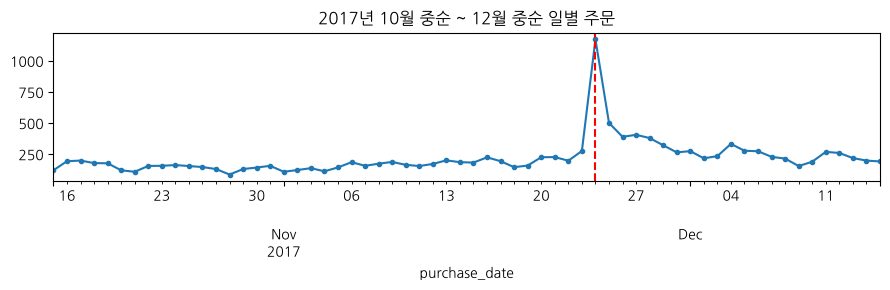

In [3]:
# 일별 주문 그래프로 보기
daily = st.daily.groupby('purchase_date').orders.sum()
ax = daily['2017-10-15':'2017-12-15'].plot(figsize=(9, 3), marker='.', title='2017년 10월 중순 ~ 12월 중순 일별 주문'); ax.axvline(pd.Timestamp('2017-11-24'), color='r', ls='--'); plt.tight_layout(); plt.show()

## 6-2. 카테고리별 BF 배수

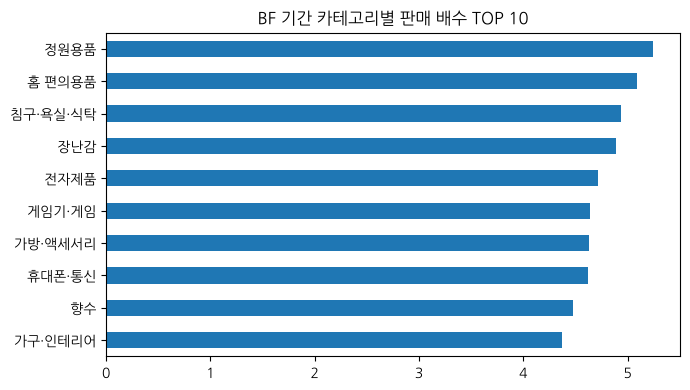

BF 주간 vs 직전 4주 같은 요일 기준 (요약표): {'정원용품': 6.43, '침구·욕실·식탁': 5.86, '전자제품': 5.33, '가방·액세서리': 5.29, '향수': 5.18, '가구·인테리어': 4.9, '장난감': 4.88, '게임기·게임': 4.85, '휴대폰·통신': 4.67, '자동차용품': 4.41}
줄어든 카테고리: {'유아용품': 2.65, '시계·선물': 2.44, '쿨 아이템': 2.06, '문구': 1.92, '사무용 가구': 0.52}


In [4]:
top = pd.Series(r['category_multiple_top10'])
ax = top.sort_values().plot(kind='barh', figsize=(7, 4), title='BF 기간 카테고리별 판매 배수 TOP 10'); plt.tight_layout(); plt.show()
print('BF 주간 vs 직전 4주 같은 요일 기준 (요약표):', bf['category_lift_top10'])
print('줄어든 카테고리:', bf['category_lift_bottom5'])

## 6-3. 내 가게 BF 성적

In [5]:
r = st.call('event_report', {'event': 'black_friday', 'seller_id': BIG})
show(r['me'])
me = r['me']
print('💬', f"내 대표 카테고리({me['my_category']})는 지난 BF에 시장 기준 {me['my_category_market_multiple']}배 팔렸고, 내 가게 주문은 평소의 {me['my_orders_multiple']:.1f}배였어요. "
      f"그 기간 내 지연율은 {me['my_late_rate_in_event']:.0%}(평소 {me['my_late_rate_overall']:.0%})였어요.")

{
 "seller_id": "6560211a19b47992c3666cc44a7e94c0",
 "my_category": "시계·선물",
 "my_category_market_multiple": 2.38,
 "my_orders_multiple": 2.2422,
 "my_late_rate_in_event": 0.1,
 "my_late_rate_overall": 0.0532
}
💬 내 대표 카테고리(시계·선물)는 지난 BF에 시장 기준 2.38배 팔렸고, 내 가게 주문은 평소의 2.2배였어요. 그 기간 내 지연율은 10%(평소 5%)였어요.


## 6-4. BF 준비 체크리스트
재고(→ 4번 발주), 발송 능력(→ 1번 지연), 쿠폰 예산(→ 1번 쿠폰), 할인 효과(→ 6-5)를 한 번에 봐요. 2018년 BF 준비에는 **2017년 BF 배수**를 써요.

In [6]:
r = st.call('event_checklist', {'seller_id': BIG, 'current_stock': 30, 'lead_time_weeks': 2})
show(r, 2000)
print('💬', f"{r['event_date']} {r['event']} 준비: 지난번 내 카테고리는 {r['category_multiple_last_time']}배({r['multiple_basis']}) 팔렸어요. "
      f"평소 주 {r['stock']['normal_weekly_units']:.0f}개인데 BF 주간엔 약 {r['stock']['event_week_units']:.0f}개가 예상돼서 지금 {r['stock']['suggested_order_now']}개를 주문하세요. "
      f"BF 때 시장 지연율이 {r['shipping']['market_late_rate_in_event']:.0%}라 보상 쿠폰 예산으로 약 {r['coupon_budget_suggestion']:.0f}헤알을 잡아두세요.")

{
 "seller_id": "6560211a19b47992c3666cc44a7e94c0",
 "event": "블랙프라이데이",
 "event_date": "2018-11-23",
 "my_category": "시계·선물",
 "category_multiple_last_time": 2.38,
 "multiple_basis": "2017년 같은 이벤트",
 "stock": {
  "normal_weekly_units": 33.9,
  "event_week_units": 60.7,
  "suggested_order_now": 104
 },
 "shipping": {
  "my_handling_days_median": 0.9216,
  "peer_handling_days_median": 1.7923,
  "market_late_rate_in_event": 0.1829,
  "warning": null
 },
 "coupon_budget_suggestion": 159.43,
 "discount_10pct": {
  "discount": 0.1,
  "category": "watches_gifts",
  "elasticity": -0.6154,
  "elasticity_basis": "전체 평균",
  "units_change": 0.067,
  "revenue_change": -0.0397,
  "note": "판매자가 잘 팔릴 때 가격을 올리는 경향이 있으면 탄력성이 실제보다 작게(할인 효과가 덜하게) 나올 수 있어요. 마진 정보가 없어 이익이 아니라 매출 기준이에요."
 }
}
💬 2018-11-23 블랙프라이데이 준비: 지난번 내 카테고리는 2.38배(2017년 같은 이벤트) 팔렸어요. 평소 주 34개인데 BF 주간엔 약 61개가 예상돼서 지금 104개를 주문하세요. BF 때 시장 지연율이 18%라 보상 쿠폰 예산으로 약 159헤알을 잡아두세요.


## 6-5. 할인 시뮬레이터
같은 상품의 시기별 가격 변화로 추정한 **가격 탄력성**으로 할인 효과를 계산해요. 대부분 카테고리에서 할인하면 판매량은 늘지만 매출은 줄어요. 마진 정보가 없어서 이익이 아니라 매출 기준이에요.

In [7]:
rows = []
for cat in ['toys', 'furniture_decor', 'housewares', 'health_beauty', 'bed_bath_table', 'sports_leisure', 'watches_gifts']:
    for disc in [0.1, 0.2]:
        r = st.call('discount_simulator', {'discount': disc, 'category': cat})
        rows.append({'카테고리': cat, '할인': f'{disc:.0%}', '탄력성': r['elasticity'], '근거': r['elasticity_basis'],
                     '판매량 변화': r['units_change'], '매출 변화': r['revenue_change']})
t = pd.DataFrame(rows); print(t.round(3).to_string(index=False))
x = st.call('discount_simulator', {'discount': 0.2, 'category': 'toys'})
print('\n💬', f"장난감은 20% 할인하면 판매량이 {x['units_change']:+.0%}, 매출은 {x['revenue_change']:+.0%} 변해요. 할인은 판매량을 늘리지만 매출을 늘리진 못하는 경우가 많아요.")

           카테고리  할인    탄력성              근거  판매량 변화  매출 변화
           toys 10% -0.974            toys   0.108 -0.003
           toys 20% -0.974            toys   0.243 -0.006
furniture_decor 10% -0.920 furniture_decor   0.102 -0.008
furniture_decor 20% -0.920 furniture_decor   0.228 -0.018
     housewares 10% -0.848      housewares   0.094 -0.016
     housewares 20% -0.848      housewares   0.208 -0.033
  health_beauty 10% -0.901   health_beauty   0.100 -0.010
  health_beauty 20% -0.901   health_beauty   0.223 -0.022
 bed_bath_table 10% -0.498  bed_bath_table   0.054 -0.052
 bed_bath_table 20% -0.498  bed_bath_table   0.118 -0.106
 sports_leisure 10% -0.312  sports_leisure   0.033 -0.070
 sports_leisure 20% -0.312  sports_leisure   0.072 -0.142
  watches_gifts 10% -0.615           전체 평균   0.067 -0.040
  watches_gifts 20% -0.615           전체 평균   0.147 -0.082

💬 장난감은 20% 할인하면 판매량이 +24%, 매출은 -1% 변해요. 할인은 판매량을 늘리지만 매출을 늘리진 못하는 경우가 많아요.


## 6-6. 다른 이벤트 (어머니날, 연인의 날, 아버지날, 크리스마스)

In [8]:
rows = []
for ev in ['mothers_day', 'valentines_day', 'fathers_day', 'christmas', 'black_friday']:
    r = st.call('event_report', {'event': ev})
    for y, v in (r['market_multiple_by_year'] or {}).items():
        rows.append({'이벤트': r['event'], '연도': y, '시장 배수': v, '이벤트 기간 지연율': r['market_late_rate_in_event']})
t = pd.DataFrame(rows); print(t.round(3).to_string(index=False))
print('\n💬 어머니날·아버지날은 평소보다 1.2~1.3배 정도 늘고, 크리스마스 직전 2주는 블랙프라이데이에 미리 사서인지 오히려 줄어요.')

        이벤트   연도  시장 배수  이벤트 기간 지연율
       어머니날 2017  1.306       0.056
       어머니날 2018  1.158       0.056
연인의 날(6/12) 2017  1.007       0.023
연인의 날(6/12) 2018  1.191       0.023
       아버지날 2017  0.962       0.069
       아버지날 2018  1.284       0.069
      크리스마스 2017  0.718       0.058
    블랙프라이데이 2017  3.704       0.183

💬 어머니날·아버지날은 평소보다 1.2~1.3배 정도 늘고, 크리스마스 직전 2주는 블랙프라이데이에 미리 사서인지 오히려 줄어요.
